In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
from gensim.parsing.preprocessing import STOPWORDS
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [2]:
d = pd.read_csv("IMDB Dataset.csv")
d.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
STOP = STOPWORDS - {"not","no","nor","never"}                # gensim list, but keep the negations (they flip sentiment)
t = "this movie was not good and never funny"
print([w for w in simple_preprocess(t) if w not in STOP])      # ours: negations kept
print([w for w in simple_preprocess(t) if w not in STOPWORDS]) # plain gensim: negations lost

['movie', 'not', 'good', 'never', 'funny']
['movie', 'good', 'funny']


In [4]:
tok = [[w for w in simple_preprocess(t.replace("<br />"," ")) if w not in STOP] for t in d.review]
y = (d.sentiment == "positive").astype(int).values

In [5]:
tk_tr, tk_te, ytr, yte = train_test_split(tok,y,test_size=0.2,random_state=42)     # split BEFORE training Word2Vec

In [6]:
w2v = Word2Vec(tk_tr,vector_size=100,window=5,min_count=5,sg=0,epochs=5)           # sg=0 -> CBOW
print(w2v.wv.most_similar("great",topn=5))

[('excellent', 0.7716450691223145), ('wonderful', 0.7534387111663818), ('fantastic', 0.7346903085708618), ('fine', 0.7232216000556946), ('good', 0.7107153534889221)]


In [7]:
vec = lambda ws: np.mean([w2v.wv[w] for w in ws if w in w2v.wv] or [np.zeros(100)],axis=0)   # document = average of its word vectors
Xtr, Xte = np.array([vec(t) for t in tk_tr]), np.array([vec(t) for t in tk_te])
print(Xtr.shape, Xte.shape)

(40000, 100) (10000, 100)


In [8]:
layers = tf.keras.layers
model = keras.Sequential([layers.Input(shape=(100,)), layers.Dense(64,activation="relu"), layers.Dropout(0.3), layers.Dense(1,activation="sigmoid")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           6,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,529 (25.50 KB)

 Trainable params: 6,529 (25.50 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
hist = model.fit(Xtr,ytr,epochs=15,batch_size=64,validation_split=0.1)

Epoch 1/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7664 - loss: 0.4877 - val_accuracy: 0.8560 - val_loss: 0.3428
Epoch 2/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1s 948us/step - accuracy: 0.8457 - loss: 0.3583 - val_accuracy: 0.8635 - val_loss: 0.3315
Epoch 3/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1s 942us/step - accuracy: 0.8472 - loss: 0.3527 - val_accuracy: 0.8620 - val_loss: 0.3275
Epoch 4/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1s 908us/step - accuracy: 0.8525 - loss: 0.3396 - val_accuracy: 0.8625 - val_loss: 0.3258
Epoch 5/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1s 934us/step - accuracy: 0.8548 - loss: 0.3427 - val_accuracy: 0.8608 - val_loss: 0.3221
Epoch 6/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1s 906us/step - accuracy: 0.8543 - loss: 0.3389 - val_accuracy: 0.8650 - val_loss: 0.3199
Epoch 7/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1s 915us/step - accuracy: 0.8569 - loss: 0.3321 - val_accuracy: 0.8612 - val_loss: 0.3236
Epoch 8/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1s 993us/step - accuracy: 0.8524 - loss: 0.3358 - va

In [10]:
#evaluate
print(model.evaluate(Xte,yte))
pred = (model.predict(Xte) > 0.5).astype(int).ravel()                  # sigmoid output -> threshold 0.5
print(classification_report(yte,pred,target_names=["negative","positive"],digits=3))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 690us/step - accuracy: 0.8582 - loss: 0.3244
[0.3234577775001526, 0.8611999750137329]
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 558us/step
              precision    recall  f1-score   support

    negative      0.891     0.820     0.854      4961
    positive      0.836     0.901     0.867      5039

    accuracy                          0.861     10000
   macro avg      0.864     0.861     0.861     10000
weighted avg      0.863     0.861     0.861     10000



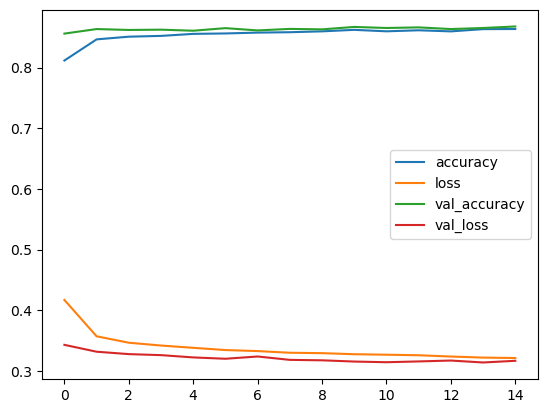

In [11]:
#plot
pd.DataFrame(hist.history).plot()
plt.show()

In [12]:
#one example
for k in (0,1):
    i = np.where((yte == k) & (pred == k))[0][0]                      # first review of class k that the model got right
    print(" ".join(tk_te[i][:12]), "... | true:", ["negative","positive"][k], "| P(positive) =", round(float(model.predict(Xte[i:i+1])[0,0]),3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
film quickly gets major chase scene increasing destruction bad thing guy hijacking ... | true: negative | P(positive) = 0.025
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
not television shows appeal different kinds fans like farscape know youngsters years ... | true: positive | P(positive) = 0.822
